# Experiment 2: CNN-LSTM refinement and tuning

## Overview

**Purpose:** improve the best model from Experiment 1 (CNN-LSTM), test whether adding hand-made features
helps, and tune the models' settings automatically for the final model.

| Item | Setup |
|---|---|
| Data | same 7 recordings and preprocessing as Experiment 1 (`PREPRO.py`) |
| Window | 150 ms (9 samples at 60 Hz), new window every 4 samples, split 60 / 20 / 20 by time |
| Models | CNN-LSTM, and CNN-LSTM-WF (same model + 32 hand-made features before the final layer) |
| Training changes | early stopping (`PATIENCE`), AdamW with weight decay, all settings in `PARAMS` |
| Tuning | Optuna search on validation accuracy: CNN-LSTM 100 trials, CNN 50, LSTM 50 |
| Results | test accuracy, macro F1, size, speed, LDA baseline, per-recording and per-gesture scores |

### Steps
1. Load and clean the recordings
2. Cut windows, split by time, balance, normalise
3. Put the data into PyTorch
4. Build the models and check them
5. Train each model with 3 seeds (early stopping)
6. Test once and compare
7. Save the best model
8. Tune the settings with Optuna

All settings are in the **Settings** cell.

### Results (150 ms window, 3 seeds, test set)

| Model | Accuracy | ± std | Macro F1 | Parameters | Model time (ms) |
|---|---|---|---|---|---|
| CNN-LSTM | 80.9% | 2.0% | 0.780 | 32,135 | 1.00 |
| **CNN-LSTM-WF** | **81.9%** | 0.2% | **0.792** | 32,423 | 1.28 |
| LDA baseline | 61.9% | – | 0.599 | – | – |

- **Validation:** CNN-LSTM-WF 84.1% ± 0.3% over 3 seeds.
- **Total delay:** about 151 ms (window + model time).
- **Ablation:** signal strength alone (RMS) 58.3%, single sample 17.5%.
- **Weakest gesture:** radial (58–65% per recording); rest and table are 90–99%.

### Tuning results (validation only, seed 0)

| Model | Best val. accuracy | Trials | Parameters | Best settings |
|---|---|---|---|---|
| **CNN-LSTM** | **86.7%** | 100 | 103,271 | 1 conv layer (64 filters, kernel 5, stride 2), LSTM memory 128 × 1 layer, hand-made features on, dropout 0.04, lr 0.0017, weight decay 0.0025, batch 64 |
| CNN | 85.9% | 50 | 239,495 | 2 conv layers (128 → 256 filters, kernel 7), dropout 0.37, lr 0.0072, weight decay 0.000025, batch 128 |
| LSTM | 84.3% | 50 | 1,326,855 | memory 256 × 3 layers, dropout 0.04, lr 0.0065, weight decay 0.0044, batch 32 |

The details are saved in best_param_exp2.json

### Conclusion
- **Hand-made features help:** +1.0 point accuracy, higher macro F1, and a much smaller spread between seeds
  (± 0.2% vs ± 2.0%), for only 288 extra parameters.
- **Tuning raises validation accuracy** from 84.1% to 86.7%; the search also chose hand-made features.
- **CNN-LSTM is the best tuned model and the smallest:** 0.8 points above the CNN with less than half its
  parameters, and 2.4 points above the LSTM at about 1/13 of its size.
- The tuned CNN-LSTM with hand-made features is carried into Experiment 3 for the final training.

In [4]:
# ---------------------------------------------------------------------------------------------
# Libraries
#
# What it does:
#     Load the libraries for data handling, plotting, scoring, the neural networks and the
#     project's own preprocessing file (PREPRO.py).
# ---------------------------------------------------------------------------------------------

import time                                                  # timing training and models
import importlib                                             # reload PREPRO.py after edits
from pathlib import Path                                     # file paths

import numpy as np                                           # arrays and maths
import pandas as pd                                          # result tables
import matplotlib.pyplot as plt                              # charts
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay   # scores and confusion matrices
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis                                 # LDA baseline

import torch                                                 # neural networks
import torch.nn as nn                                        # layers (Conv1d, LSTM, Linear, ...)
import torch.nn.functional as F                              # functions such as padding

import PREPRO as pp                                          # loading, cleaning, windows, split
importlib.reload(pp)                                         # picks up any edits to PREPRO.py without restarting the kernel
from IPython.display import display                          # show formatted tables from inside a cell

## Settings

| Group | Setting | What it does |
|---|---|---|
| Data | `DATA_FOLDER`, `CHANNELS`, `GESTURES` | where the recordings are, which columns are signal, which gestures to classify |
| Signal | `SAMPLE_RATE` | readings per second per channel. Step 1 prints the rate measured from `Time`: make them match |
| Signal | `PREP` | everything passed to `pp.preprocess` (outliers, notch, band-pass, causal or zero-phase, per file) |
| Windows | `WINDOW_MS`, `STEP` | window length (the system's delay) and the gap between window starts |
| Split | `VAL_FRAC`, `TEST_FRAC` | the last part of every recording held out for validation and test |
| Split | `MAX_GAP_MS` | skip windows that jump over missing rows (e.g. removed outliers). `None` = off |
| Balance | `BALANCE_TRAIN`, `DATA_SEED` | cap training gestures at the median count; fixed seed so the data never changes between runs |
| Training | `BATCH_SIZE`, `EPOCHS`, `LEARNING_RATE`, `SEEDS` | training settings; every model is trained once per seed |

In [5]:
# ---------------------------------------------------------------------------------------------
# Settings
#
# What it does:
#     Every data, signal, window, split and training setting in one place. Changing a value here
#     and re-running from the top changes the whole experiment.
# ---------------------------------------------------------------------------------------------

# ---------- data ----------
DATA_FOLDER = "Data"                                         # folder with one sub-folder per recording
CHANNELS = [f"V{i+1}" for i in range(8)]                     # signal columns V1..V8
GESTURES = {"fist": 1, "flexion": 2, "extension": 3, "radial": 4, "ulnar": 5, "rest": 6, "table": 7}   # gesture -> number

# ---------- signal (passed to pp.preprocess) ----------
SAMPLE_RATE = 60                                             # readings per second per channel (Hz)
PREP = dict(
    sample_rate=SAMPLE_RATE,                                 # used to design the filters
    resample=False,                                          # True: even time grid from Time; False: rows as recorded
    outlier_z=3.0,                                           # drop rows beyond 3 std devs; None = keep all
    zero_centre=True,                                        # subtract each channel's mean
    notch_hz=None,                                           # mains-hum notch filter; None = off
    low_hz=1,                                                # band-pass lower edge (Hz)
    high_hz=8,                                               # band-pass upper edge (Hz)
    filter_order=4,                                          # filter steepness
    causal=True,                                             # filters only look at the past, as in live use
    per_file=True,                                           # outliers and filters per recording
)

# ---------- windows and split (passed to pp.make_datasets) ----------
WINDOW_MS = 150                                              # window length = delay (ms)
WINDOW_SIZE = SAMPLE_RATE * WINDOW_MS // 1000                # samples per window (9 at 60 Hz)
STEP = 4                                                     # samples between window starts
SPLIT_BY = "chrono"                                          # each recording: train, then validation, then test
VAL_FRAC, TEST_FRAC = 0.2, 0.2                               # 60 / 20 / 20 split
MAX_GAP_MS = None                                            # skip windows over a real gap; None = off
BALANCE_TRAIN = True                                         # cap training gestures at the median count
DATA_SEED = 0                                                # fixed seed: the data never changes between runs

# ---------- training ----------
BATCH_SIZE = 64                                              # windows per weight update
EPOCHS = 60                                                  # upper limit; training stops early
PATIENCE = 8                                                 # stop after this many epochs without a better val accuracy
LEARNING_RATE = 0.001                                        # step size of each weight update
SEEDS = [0, 1, 2]                                            # model seeds: starting weights, batch order, dropout

print(f"window: {WINDOW_MS} ms = {WINDOW_SIZE} samples at {SAMPLE_RATE} Hz, step {STEP}")   # quick check

window: 150 ms = 9 samples at 60 Hz, step 4


## Step 1: load and clean the recordings

`pp.preprocess` reads every file in `DATA_FOLDER`, removes outlier rows, zero-centres each channel and applies
the notch and band-pass filters set in `PREP`. It returns one table with columns
`file, file_idx, Time, V1..V8, Gesture`, so the time stamps are kept for later use.

Check the printed **measured rate**: if it differs from `SAMPLE_RATE`, the filter edges and window length
in milliseconds are not what the settings say.

In [6]:
# ---------------------------------------------------------------------------------------------
# Step 1: load and clean the recordings
#
# What it does:
#     Read every recording, remove outliers, zero-centre and filter each channel (settings in PREP).
#     Returns one table with columns file, file_idx, Time, V1..V8, Gesture.
# ---------------------------------------------------------------------------------------------

PREP_RAW_TIME = {**PREP, "resample": False}                  # copy of PREP with rows kept as recorded (no time grid)
data = pp.preprocess(DATA_FOLDER, channels=CHANNELS, **PREP_RAW_TIME)   # load + clean; prints a timing report

loaded 7 files, 41709 rows
recorded timing per file (gaps between rows, ms):
        gesture  rows  length (s)  rate (Hz)  short <=10 ms (%)  pauses  longest pause (s)  duplicates
file                                                                                                  
01         fist  8678       269.5       53.4               41.7      89                6.0           0
02      flexion  5098       201.5       52.5               36.7      79               10.3           1
03    extension  5485       225.2       52.7               36.4      73               44.1           0
04       radial  4334       163.3       52.9               37.3      68               31.4           0
05        ulnar  3816       138.5       54.5               38.8      56                8.1           0
06         rest  6328       119.1       53.2               37.8       2                0.1           1
07        table  7970       155.6       51.2               34.8       0                0.1         

## Step 2: windows, split, balance and normalise

`pp.make_datasets` cuts every recording into windows of `WINDOW_SIZE` samples (a new window every `STEP`
samples), keeping only windows with a single gesture label. Each recording is split along time: the first
60% for training, the next 20% for validation and the last 20% for testing. Windows that cross a cut are
dropped, and a check confirms that no raw sample is shared between splits.

Training gestures are then capped at the median count, and every channel is normalised with
statistics from the training windows only.

In [7]:
# ---------------------------------------------------------------------------------------------
# Step 2: windows, split, balance and normalise
#
# What it does:
#     Cut every recording into windows, split each recording by time into train / validation /
#     test, cap training gestures at the median count and normalise with training statistics.
#
# Steps:
#     1. Make the datasets with pp.make_datasets.
#     2. Unpack the windows, labels and details used by later steps.
# ---------------------------------------------------------------------------------------------

d = pp.make_datasets(data, WINDOW_SIZE, STEP, channels=CHANNELS, gestures=GESTURES,        # 1. windows of WINDOW_SIZE, one every STEP
                     val_frac=VAL_FRAC, test_frac=TEST_FRAC, max_gap_ms=MAX_GAP_MS,        #    split fractions, gap check
                     balance_train=BALANCE_TRAIN, data_seed=DATA_SEED)                     #    capping, fixed data seed

X_train, y_train = d["X_train"], d["y_train"]               # 2. training windows [n, time, 8] and labels
X_val,   y_val   = d["X_val"],   d["y_val"]                 #    validation (early stopping, model choice)
X_test,  y_test  = d["X_test"],  d["y_test"]                #    test (used once, at the end)
test_file        = d["test_file"]                           #    recording each test window came from
GESTURE_NAMES    = d["gesture_names"]                       #    class number -> gesture name
N_CLASSES        = d["n_classes"]                           #    number of gestures (7)
channel_mean, channel_std = d["channel_mean"], d["channel_std"]   # normalisation, needed again for live use

                windows  train  val  test  dropped
file gesture                                      
01   fist          1930   1157  384   385        4
02   flexion       1124    674  223   223        4
03   extension     1229    737  244   244        4
04   radial         960    575  190   191        4
05   ulnar          859    515  170   170        4
06   rest          1454    871  289   290        4
07   table         1812   1086  361   361        4 

windows: 9 samples, step 4; train 9424, val 1861, test 1864; samples shared between splits: 0
augmented training set: 4712 -> 9424 windows (x2, Gaussian noise std 0.05 of channel std)
capped each training gesture at 737 windows:
  fist          1157 ->   737
  flexion        674 ->   674
  extension      737 ->   737
  radial         575 ->   575
  ulnar          515 ->   515
  rest           871 ->   737
  table         1086 ->   737


## Step 3: put the data into PyTorch

In [8]:
# ---------------------------------------------------------------------------------------------
# Step 3: put the data into PyTorch
#
# What it does:
#     Wrap the windows and labels as PyTorch datasets and loaders (batches), and print the shape
#     of one batch as a check.
# ---------------------------------------------------------------------------------------------

train_data = torch.utils.data.TensorDataset(torch.tensor(X_train), torch.tensor(y_train))   # windows + labels
val_data   = torch.utils.data.TensorDataset(torch.tensor(X_val),   torch.tensor(y_val))
test_data  = torch.utils.data.TensorDataset(torch.tensor(X_test),  torch.tensor(y_test))

train_loader = torch.utils.data.DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)   # shuffled batches for training
val_loader   = torch.utils.data.DataLoader(val_data,   batch_size=BATCH_SIZE)                 # fixed order for scoring
test_loader  = torch.utils.data.DataLoader(test_data,  batch_size=BATCH_SIZE)

batch_x, batch_y = next(iter(train_loader))                  # one batch, used by the shape checks
print("one batch of windows:", tuple(batch_x.shape), "(batch, time steps, channels)")
print("one batch of labels: ", tuple(batch_y.shape),
      f"values {int(batch_y.min())}..{int(batch_y.max())}")  # labels 0 .. N_CLASSES-1

one batch of windows: (64, 9, 8) (batch, time steps, channels)
one batch of labels:  (64,) values 0..6


## Step 4: the models

In [9]:
def pad_left(x, kernel_size, dilation=1, stride=1):
    """
    What it does:
        Add zeros on the left (the past) of the time axis, so a convolution keeps the length and
        never uses a future sample. Return the padded tensor.

    Steps:
        1. Causal padding: (kernel_size - 1) * dilation zeros.
        2. With stride > 1: extra zeros so the last filter position ends on the newest sample.
        3. Pad the last dimension (time) on the left only.
    """
    pad = (kernel_size - 1) * dilation + (-(x.shape[-1] - 1)) % stride   # 1-2. number of zeros
    return F.pad(x, (pad, 0))                                             # 3. (left, right) on the time axis

### 4a. LSTM

Same model as Experiment 1 (see Experiment 1 for how an LSTM works). Only the way it is set up changed.

| | Experiment 1 | Experiment 2 |
|---|---|---|
| Settings | fixed inside the class | arguments, set in `PARAMS` and tunable by Optuna |
| Memory size (`hidden`) | 64 | 64 (default), tuning range 32–128 |
| Layers | 1 | 1 (default), tuning range 1–2 |
| Dropout | 0.3 before the final layer | 0.3, also between stacked LSTM layers when `layers` = 2 |
| Run in this experiment | yes | no: commented out in `MODEL_CLASSES` |

In [10]:
class LSTMModel(nn.Module):
    """
    What it does:
        Classify one window with an LSTM (memory only, no convolution).

    Steps:
        1. LSTM reads the 8 channel values at every time step and updates its memory.
        2. Keep the output of the last time step (summary of the whole window).
        3. Dropout, then a linear layer gives one score per gesture.

    Settings: hidden = memory size, layers = stacked LSTMs, dropout = share of values switched off
    in training.
    """
    def __init__(self, n_channels=8, n_classes=7, hidden=64, layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_channels, hidden_size=hidden, num_layers=layers,
                            batch_first=True, dropout=dropout)      # input [batch, time, 8]
        self.dropout = nn.Dropout(dropout)                   # before the final layer
        self.fc = nn.Linear(hidden, n_classes)               # memory -> gesture scores

    def all_steps(self, x):                 # x: [batch, time, 8]
        """LSTM output at every time step: [batch, time, hidden]."""
        out, _ = self.lstm(x)               # final memory states not needed
        return out                          # [batch, time, hidden]

    def forward(self, x):
        """Gesture scores for each window: last time step -> dropout -> linear. [batch, n_classes]."""
        last_step = self.all_steps(x)[:, -1, :]              # newest time step only
        return self.fc(self.dropout(last_step))

### 4b. CNN

Same idea as Experiment 1 (see Experiment 1 for how a CNN works), but resized for the 150 ms window.

| | Experiment 1 | Experiment 2 |
|---|---|---|
| Settings | fixed inside the class | arguments, set in `PARAMS` and tunable by Optuna |
| Conv layers | 4 | 2 (default), tuning range 1–4 |
| Dilation | 1, 2, 4, 8 | none (every layer reads neighbouring samples) |
| Filters | 32, 32, 64, 64 | `width`, then 2 × `width` (32, 64) |
| Reach | 61 samples | 1 + (5 − 1) × 2 = **9 samples** = the window |
| Parameters | 38,151 | 12,263 |
| Run in this experiment | yes | no: commented out in `MODEL_CLASSES` |

**Why it changed:** the window is only 9 samples. The Experiment 1 CNN could reach 61 samples back, so
most of what its deeper layers read was zero padding, not signal. Two plain layers cover the window
exactly, with about a third of the parameters.

**Reach rule (used in tuning):** reach must be between `WINDOW_SIZE` and 2 × `WINDOW_SIZE`. Shorter misses
part of the window; longer mostly reads padding.

In [11]:
class CNNModel(nn.Module):
    """
    What it does:
        Classify one window with stacked causal 1D convolutions (patterns only, no memory).

    Steps:
        1. Flip the window to channels-first for Conv1d.
        2. Each layer: pad on the left, convolve, batch norm, ReLU.
        3. Keep the output at the newest time step.
        4. Dropout, then a linear layer gives one score per gesture.

    Settings: width = filters in the first layer (later layers 2 x width), kernel_size = samples per
    filter, n_layers = number of conv layers. Reach = 1 + (kernel_size - 1) x n_layers samples.
    """
    def __init__(self, n_channels=8, n_classes=7, width=32, kernel_size=5, n_layers=2, dropout=0.3):
        super().__init__()
        self.kernel_size = kernel_size                       # same filter size in every layer
        widths = [width] + [2 * width] * (n_layers - 1)      # e.g. 32, 64
        self.convs, self.bns = nn.ModuleList(), nn.ModuleList()   # lists PyTorch can train
        n_in = n_channels                                    # first layer reads the 8 electrodes


        for w in widths:                                     # one conv + batch norm per layer
            self.convs.append(nn.Conv1d(n_in, w, kernel_size))   # n_in inputs -> w filters
            self.bns.append(nn.BatchNorm1d(w))               # keeps each filter's output on a steady scale
            n_in = w                                         # next layer reads this layer's output
        self.dropout = nn.Dropout(dropout)                   # switches off random values in training
        self.fc = nn.Linear(n_in, n_classes)                 # last layer's filters -> gesture scores

    def all_steps(self, x):                 # x: [batch, time, 8]
        """Conv output at every time step: [batch, time, last layer's filters]."""
        x = x.transpose(1, 2)               # -> [batch, 8, time]
        for conv, bn in zip(self.convs, self.bns):
            x = torch.relu(bn(conv(pad_left(x, self.kernel_size))))   # pad, convolve, normalise, keep positives
        return x.transpose(1, 2)            # -> [batch, time, channels]

    def forward(self, x):
        """Gesture scores for each window: last time step -> dropout -> linear. [batch, n_classes]."""
        last_step = self.all_steps(x)[:, -1, :]              # newest time step only
        return self.fc(self.dropout(last_step))

### 4c. CNN-LSTM and CNN-LSTM-WF

Same CNN-then-LSTM design as Experiment 1, with a smaller front-end and an option for hand-made features.

| | Experiment 1 | Experiment 2 |
|---|---|---|
| Settings | fixed inside the class | arguments, set in `PARAMS` and tunable by Optuna |
| Conv filters (layer 1, layer 2) | 32, 64 | 32, 32 (`width` in both) |
| Stride on layer 2 | 2 | 2 (tunable 1–2); padding also adjusted so the last filter always ends on the newest sample |
| LSTM input size | 64 | 32 |
| LSTM memory, layers | 64, 1 | 64, 1 (default), tunable |
| Hand-made features | none | optional (`use_features=True`): **CNN-LSTM-WF** |
| Parameters | 45,543 | 32,135 (32,423 with features) |

**Hand-made features (WF = with features):** RMS, MAV, WL and ZC for each of the 8 channels (32 numbers) are
computed from the raw window, rescaled with batch norm, and joined with the LSTM's last output just before
the final layer:


![CNN-LSTM-WF](Images/cnn_lstm_wf.png)

**Why:** in Experiment 1, signal strength alone (RMS + LDA) already reached 58.3%. Giving the model these
classic sEMG measures directly means the CNN and LSTM do not have to learn them from 9 samples, and they
cost only 288 extra parameters.

In [12]:
def hand_made_features_torch(x):
    """
    What it does:
        Compute 4 classic sEMG features per channel over the whole window (torch version, used
        inside the model so live windows get the same features).

    Steps:
        1. RMS: square, average over time, square root (signal strength).
        2. MAV: average absolute value (average size).
        3. WL: sum of absolute changes between neighbouring samples (how much it wiggles).
        4. ZC: number of sign changes (zero crossings).
        5. Join the four [batch, 8] blocks into [batch, 32].
    """
    rms = torch.sqrt(torch.mean(x ** 2, dim=1))                      # 1. signal strength        [batch, 8]
    mav = torch.mean(torch.abs(x), dim=1)                            # 2. average size           [batch, 8]
    wl  = torch.sum(torch.abs(torch.diff(x, dim=1)), dim=1)          # 3. how much it wiggles    [batch, 8]
    zc  = torch.sum(torch.diff(torch.sign(x), dim=1) != 0, dim=1).float()   # 4. zero crossings  [batch, 8]
    return torch.cat([rms, mav, wl, zc], dim=1)                      # 5. side by side           [batch, 32]

In [13]:
class CNNFrontEnd(nn.Module):
    """
    What it does:
        Turn the raw window into a shorter sequence of pattern features for the LSTM.

    Steps:
        1. Flip the window to channels-first for Conv1d.
        2. Conv layer 1: pad on the left, convolve, batch norm, ReLU.
        3. Conv layer 2: same, with the stride (2 = half as many time steps).
        4. Flip back to time-first for the LSTM.
    """
    def __init__(self, n_channels=8, width=32, kernel_size=5, stride=2):
        super().__init__()
        self.kernel_size, self.stride = kernel_size, stride  # kept for padding in forward
        self.conv1 = nn.Conv1d(n_channels, width, kernel_size)   # 8 electrodes -> width filters
        self.bn1 = nn.BatchNorm1d(width)

        self.conv2 = nn.Conv1d(width, width, kernel_size, stride=stride)   # same width, fewer time steps
        self.bn2 = nn.BatchNorm1d(width)
        self.out_channels = width                            # features per step -> LSTM input size

    def forward(self, x):                   # x: [batch, time, 8]
        """Pattern features: [batch, time / stride, width]."""
        x = x.transpose(1, 2)               # -> [batch, 8, time]
        x = torch.relu(self.bn1(self.conv1(pad_left(x, self.kernel_size))))                       # layer 1
        x = torch.relu(self.bn2(self.conv2(pad_left(x, self.kernel_size, stride=self.stride))))   # layer 2 (strided)
        return x.transpose(1, 2)            # -> [batch, time / stride, width]


class CNNLSTMModel(nn.Module):
    """
    What it does:
        Classify one window with the CNN front-end (patterns) followed by an LSTM (order over time),
        optionally joined with 32 hand-made features before the final layer.

    Steps:
        1. CNNFrontEnd turns the window into a sequence of pattern features.
        2. LSTM reads that sequence step by step.
        3. Keep the LSTM output at the last time step.
        4. If use_features: compute RMS, MAV, WL, ZC from the raw window, rescale with batch norm,
           and join them with the LSTM output (hidden + 32 numbers).
        5. Dropout, then a linear layer gives one score per gesture.
    """
    def __init__(self, n_channels=8, n_classes=7, width=32, kernel_size=5, stride=2,
                 hidden=64, layers=2, dropout=0.3, use_features=False):
        super().__init__()
        self.cnn = CNNFrontEnd(n_channels, width, kernel_size, stride)   # pattern part

        self.lstm = nn.LSTM(input_size=self.cnn.out_channels, hidden_size=hidden, num_layers=layers,
                            batch_first=True, dropout=dropout if layers > 1 else 0.0)   # dropout only between stacked LSTMs

        self.dropout = nn.Dropout(dropout)                   # before the final layer

        # Hand-made features (optional): computed from the raw window, they skip the CNN and LSTM
        # and are joined with the LSTM's last output just before the final linear layer.
        self.use_features = use_features
        n_features = 4 * n_channels if use_features else 0   # 32 extra numbers, or none
        if use_features:
            self.feature_bn = nn.BatchNorm1d(n_features)     # puts the 32 features on one scale

        self.fc = nn.Linear(hidden + n_features, n_classes)  # LSTM output (+ features) -> gesture scores

    def all_steps(self, x):
        """LSTM output at every (strided) time step: [batch, time / stride, hidden]."""
        out, _ = self.lstm(self.cnn(x))     # CNN patterns, then LSTM
        return out

    def forward(self, x):
        """Gesture scores for each window: [batch, n_classes]."""
        last_step = self.all_steps(x)[:, -1, :]              # newest time step only
        if self.use_features:
                    features = self.feature_bn(hand_made_features_torch(x))   # 32 features from the raw window
                    last_step = torch.cat([last_step, features], dim=1)     # join: hidden + 32
        return self.fc(self.dropout(last_step))

### 4d. Build and check the models


`MODEL_CLASSES` lists the models in a fixed order. Every later step loops over it, so to leave a model out, delete its line here.

The seed is reset before building each model, so every model starts from the same kind of random weights. That keeps the comparison fair.

In [14]:
# ---------------------------------------------------------------------------------------------
# Models, settings and building
#
# What it does:
#     List the models to run, keep every model setting in PARAMS, and build each model once to
#     check its shapes and size.
#
# Steps:
#     1. MODEL_CLASSES: models every later step loops over (commented out = skipped).
#     2. PARAMS: model settings, plus the training settings (learning rate, weight decay, batch size).
#     3. build_model: create one untrained model with a fixed seed.
#     4. Build each model and print input -> output shapes and parameter count.
# ---------------------------------------------------------------------------------------------

MODEL_CLASSES = {#"LSTM": LSTMModel,                        # 1. commented out = not run
                #"CNN": CNNModel,
                "CNN-LSTM": CNNLSTMModel,
                "CNN-LSTM-WF": CNNLSTMModel                  #    same class, with hand-made features
                }

# every setting of every model in one place; tuning (Step 8) replaces these
PARAMS = {                                                   # 2. model settings
    "LSTM":     dict(hidden=64, layers=1, dropout=0.3),
    "CNN":      dict(width=32, kernel_size=5, n_layers=2, dropout=0.3),
    "CNN-LSTM": dict(width=32, kernel_size=5, stride=2, hidden=64, layers=1, dropout=0.3),
    "CNN-LSTM-WF": dict(width=32, kernel_size=5, stride=2, hidden=64, layers=1, dropout=0.3, use_features=True),

}
for p in PARAMS.values():                                   # training settings, also tunable
    p.update(lr=LEARNING_RATE, weight_decay=1e-6, batch_size=BATCH_SIZE)

TRAIN_KEYS = ("lr", "weight_decay", "batch_size")           # these go to the optimiser, not the model


def build_model(name, seed=0, params=None):
    """
    What it does:
        Create one untrained model with a fixed seed.

    Steps:
        1. Use the given params, otherwise PARAMS[name].
        2. Set the seed, so the same seed always gives the same starting weights.
        3. Drop the training-only settings (lr, weight_decay, batch_size).
        4. Build the model class from MODEL_CLASSES with N_CLASSES outputs.
    """
    params = params or PARAMS[name]                         # 1. settings
    torch.manual_seed(seed)                                 # 2. same seed -> same starting weights
    model_args = {k: v for k, v in params.items() if k not in TRAIN_KEYS}   # 3. model settings only
    return MODEL_CLASSES[name](n_classes=N_CLASSES, **model_args)           # 4. the model


for name in MODEL_CLASSES:                                  # 4. shape and size check
    model = build_model(name)
    model.eval()                                            # dropout off, batch norm fixed
    with torch.no_grad():                                   # no training here
        steps = model.all_steps(batch_x)                    # output at every time step
        scores = model(batch_x)                             # gesture scores
    n_params = sum(p.numel() for p in model.parameters())   # model size
    print(f"{name:9s} input {tuple(batch_x.shape)} -> every step {tuple(steps.shape)} "
          f"-> scores {tuple(scores.shape)}   parameters: {n_params:,}")

CNN-LSTM  input (64, 9, 8) -> every step (64, 5, 64) -> scores (64, 7)   parameters: 32,135
CNN-LSTM-WF input (64, 9, 8) -> every step (64, 5, 64) -> scores (64, 7)   parameters: 32,423


In [15]:
# ---------------------------------------------------------------------------------------------
# Shape check: one batch through the CNN-LSTM
#
# What it does:
#     Run one batch through the CNN-LSTM layer by layer and print the shape after each step.
#     No training happens. (Hand-made features are not shown here.)
#
# Steps:
#     1. Build the CNN-LSTM and switch it to evaluation mode.
#     2. Flip the window to channels-first; conv layer 1 (padded, length unchanged).
#     3. Conv layer 2 with the stride (half the time steps).
#     4. Flip back to time-first and run the LSTM over every step.
#     5. Keep the last time step and turn it into one score per gesture.
# ---------------------------------------------------------------------------------------------

model = build_model("CNN-LSTM")                              # 1. untrained model, fixed seed
model.eval()                                                 #    dropout off, batch norm fixed
cnn = model.cnn                                              #    the CNN front-end inside the model
k, s = cnn.kernel_size, cnn.stride                           #    filter size and stride
with torch.no_grad():                                        #    shapes only
    x = batch_x;                                  print("input:              ", tuple(x.shape))   # [batch, time, 8]
    x = x.transpose(1, 2);                        print("flip for Conv1d:    ", tuple(x.shape))   # 2. [batch, 8, time]
    x = pad_left(x, k);                           print("pad on the left:    ", tuple(x.shape))   #    zeros added in the past
    x = torch.relu(cnn.bn1(cnn.conv1(x)));        print("conv1:              ", tuple(x.shape))   #    [batch, width, time]
    x = pad_left(x, k, stride=s);                 print("pad on the left:    ", tuple(x.shape))   # 3.
    x = torch.relu(cnn.bn2(cnn.conv2(x)));        print(f"conv2 (stride {s}):   ", tuple(x.shape))  #    time / stride
    x = x.transpose(1, 2);                        print("flip for LSTM:      ", tuple(x.shape))   # 4. time first
    x, _ = model.lstm(x);                         print("LSTM, every step:   ", tuple(x.shape))   #    [batch, steps, hidden]
    x = x[:, -1, :];                              print("last step only:     ", tuple(x.shape))   # 5. [batch, hidden]
    x = model.fc(x);                              print("gesture scores:     ", tuple(x.shape))   #    [batch, 7]

input:               (64, 9, 8)
flip for Conv1d:     (64, 8, 9)
pad on the left:     (64, 8, 13)
conv1:               (64, 32, 9)
pad on the left:     (64, 32, 13)
conv2 (stride 2):    (64, 32, 5)
flip for LSTM:       (64, 5, 32)
LSTM, every step:    (64, 5, 64)
last step only:      (64, 64)
gesture scores:      (64, 7)


## Step 5: training 

In [16]:
loss_fn = nn.CrossEntropyLoss()        # Loss function: compares gesture scores with true labels.


def train_one_epoch(model, loader, optimizer):
    """
    What it does:
        Train the model for one pass over all training windows. Return average loss and accuracy.

    Steps:
        1. Switch the model to training mode (dropout on, batch norm updates its statistics).
        2. Take one batch of windows and labels.
        3. Compute gesture scores (forward pass).
        4. Compute the loss between scores and labels.
        5. Clear old gradients.
        6. Compute new gradients (backward pass).
        7. Update the weights.
        8. Add the batch loss and correct predictions to running totals.
        9. Repeat steps 2-8 for every batch.
        10. Return average loss and accuracy.
    """
    model.train()                                              # 1. Training mode.
    total_loss, correct, count = 0.0, 0, 0
    for windows, labels in loader:                             # 2. One batch.
        scores = model(windows)                                # 3. Forward pass.
        loss = loss_fn(scores, labels)                         # 4. Loss.
        optimizer.zero_grad()                                  # 5. Clear gradients.
        loss.backward()                                        # 6. Backward pass.
        optimizer.step()                                       # 7. Update weights.
        total_loss += loss.item() * len(labels)                # 8. Sum loss over windows.
        correct += (scores.argmax(dim=1) == labels).sum().item()   # 8. Count correct predictions.
        count += len(labels)
    return total_loss / count, correct / count                 # 10. Average loss, accuracy.


def evaluate(model, loader):
    """
    What it does:
        Score the model on a dataset without changing any weights. Return average loss and accuracy.

    Steps:
        1. Switch the model to evaluation mode (dropout off, batch norm uses stored statistics).
        2. Turn off gradient tracking.
        3. Take one batch of windows and labels.
        4. Compute gesture scores.
        5. Add the batch loss and correct predictions to running totals.
        6. Repeat steps 3-5 for every batch.
        7. Return average loss and accuracy.
    """
    model.eval()                                               # 1. Evaluation mode.
    total_loss, correct, count = 0.0, 0, 0
    with torch.no_grad():                                      # 2. No gradients.
        for windows, labels in loader:                         # 3. One batch.
            scores = model(windows)                            # 4. Forward pass only.
            total_loss += loss_fn(scores, labels).item() * len(labels)   # 5. Sum loss.
            correct += (scores.argmax(dim=1) == labels).sum().item()     # 5. Count correct.
            count += len(labels)
    return total_loss / count, correct / count                 # 7. Average loss, accuracy.


def train_model(name, seed=0, params=None, trial=None):
    """
    What it does:
        Train one model from scratch with early stopping. Keep the weights from the epoch with the
        best validation accuracy. Return the training history.
        Normal mode (trial=None): print progress, save best weights to file.
        Tuning mode (trial given): report to Optuna, allow early cut-off, save nothing.

    Steps:
        1. Load settings: given params, otherwise PARAMS[name].
        2. Build the model with the given seed.
        3. Build the training loader (batch size from settings, shuffle order fixed by seed).
        4. Build the optimiser (AdamW: learning rate and weight decay from settings).
        5. For each epoch:
           5a. Train for one epoch.
           5b. Score on the validation set.
           5c. Record losses and accuracies.
           5d. If validation accuracy is a new best: store a copy of the weights, reset wait counter.
               Otherwise: increase wait counter.
           5e. Tuning mode: report validation accuracy; stop the trial if Optuna marks it as poor.
               Normal mode: print epoch results.
           5f. Stop if wait counter reaches PATIENCE.
        6. Normal mode: save best weights to "best_{name}_seed{seed}.pt".
        7. Return the history.
    """
    params = params or PARAMS[name]                            # 1. Settings.
    model = build_model(name, seed, params)                    # 2. Model, seeded weights.
    loader = torch.utils.data.DataLoader(train_data, batch_size=params["batch_size"], shuffle=True,
                                         generator=torch.Generator().manual_seed(seed))   # 3. Seeded shuffle.
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"],
                                  weight_decay=params["weight_decay"])                  # 4. Optimiser.
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}         #    one value per epoch
    best_val_acc, best_state, wait = 0.0, None, 0                                       #    best so far, its weights, epochs without improvement

    for epoch in range(1, EPOCHS + 1):                         # 5. Epoch loop (EPOCHS = upper limit).
        train_loss, train_acc = train_one_epoch(model, loader, optimizer)    # 5a. Train.
        val_loss, val_acc = evaluate(model, val_loader)                      # 5b. Validate.
        history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)   # 5c. Record.
        history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:                             # 5d. New best epoch.
            best_val_acc, wait = val_acc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}  # Copy weights in memory.
        else:
            wait += 1                                          # 5d. No improvement.

        if trial is not None:                                  # 5e. Tuning mode.
            trial.report(val_acc, epoch)                       # Send score to Optuna.
            if trial.should_prune():                           # Poor compared with earlier trials.
                raise optuna.TrialPruned()                     # End this trial now.
        else:                                                  # 5e. Normal mode.
            print(f"  epoch {epoch:2d}  train acc {train_acc:.1%}  val acc {val_acc:.1%}"
                  f"{'  <- best' if wait == 0 else ''}")       #     progress line
        if wait >= PATIENCE:                                   # 5f. Early stop.
            break

    if trial is None:                                          # 6. Normal mode only.
        torch.save(best_state, f"best_{name}_seed{seed}.pt")   # One file write per model and seed.
    return history                                             # 7. History.

In [17]:
# ---------------------------------------------------------------------------------------------
# Train every model with every seed
#
# What it does:
#     Train each model once per seed, record the training time, and pick the seed with the best
#     validation accuracy for the plots and the saved model.
#
# Steps:
#     1. For each model and each seed: train from scratch and time the run.
#     2. Pick the seed whose best validation accuracy is highest.
#     3. Keep that seed's training history for the plots.
#     4. Store the average training time per run.
#     5. Print the mean ± std of the best validation accuracy over all seeds.
# ---------------------------------------------------------------------------------------------

histories, training_seconds, chosen_seed = {}, {}, {}    # results per model name

for name in MODEL_CLASSES:
    run_histories, times = {}, []                        # this model: history and time per seed
    for seed in SEEDS:                                   # 1. one full training run per seed
        print(f"Training {name}, seed {seed}")
        start_time = time.time()
        run_histories[seed] = train_model(name, seed)    #    trains, saves best_{name}_seed{seed}.pt
        times.append(time.time() - start_time)           #    seconds for this run

    # the seed with the best validation accuracy is used for the plots and saved model
    chosen_seed[name] = max(SEEDS, key=lambda s: max(run_histories[s]["val_acc"]))   # 2. best seed (validation only)
    histories[name] = run_histories[chosen_seed[name]]                                # 3. its history, for the plots
    training_seconds[name] = float(np.mean(times))                                    # 4. average time per run
    vals = [max(run_histories[s]["val_acc"]) for s in SEEDS]                          #    best val accuracy of each seed
    print(f"  {name}: validation accuracy {np.mean(vals):.1%} ± {np.std(vals):.1%} "  # 5. mean ± spread over seeds
          f"over {len(SEEDS)} seeds, using seed {chosen_seed[name]}\n")

Training CNN-LSTM, seed 0


  epoch  1  train acc 53.0%  val acc 67.0%  <- best
  epoch  2  train acc 74.0%  val acc 74.3%  <- best
  epoch  3  train acc 78.7%  val acc 78.5%  <- best
  epoch  4  train acc 81.4%  val acc 77.4%
  epoch  5  train acc 82.7%  val acc 80.1%  <- best
  epoch  6  train acc 83.9%  val acc 81.2%  <- best
  epoch  7  train acc 85.0%  val acc 80.5%
  epoch  8  train acc 86.3%  val acc 80.8%
  epoch  9  train acc 87.3%  val acc 82.5%  <- best
  epoch 10  train acc 87.7%  val acc 81.1%
  epoch 11  train acc 88.6%  val acc 82.4%
  epoch 12  train acc 88.9%  val acc 82.2%
  epoch 13  train acc 89.1%  val acc 82.5%  <- best
  epoch 14  train acc 89.9%  val acc 80.6%
  epoch 15  train acc 90.6%  val acc 85.0%  <- best
  epoch 16  train acc 90.7%  val acc 84.7%
  epoch 17  train acc 90.7%  val acc 82.9%
  epoch 18  train acc 91.1%  val acc 84.6%
  epoch 19  train acc 91.2%  val acc 82.3%
  epoch 20  train acc 91.6%  val acc 84.1%
  epoch 21  train acc 91.3%  val acc 85.4%  <- best
  epoch 22  trai

Solid lines are validation accuracy, dotted lines are training accuracy. A big gap between a model's two lines means it is memorising the training data (overfitting). The saved version of each model is the one from its best validation epoch, not the last one.

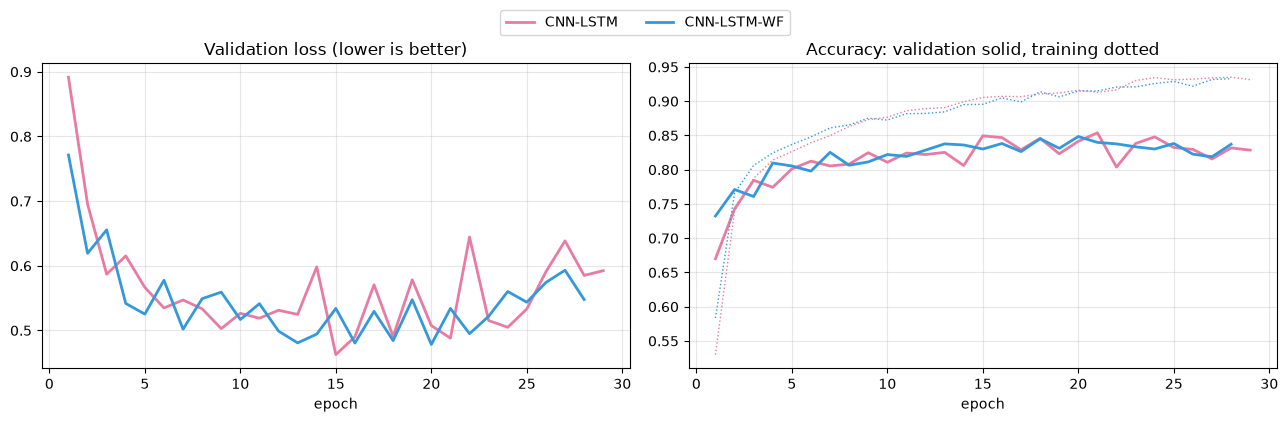

In [18]:
# ---------------------------------------------------------------------------------------------
# Training curves
#
# What it does:
#     Plot how each model learned over the epochs, using the history of its chosen seed.
#     Left: validation loss. Right: validation accuracy (solid) and training accuracy (dotted).
#
# Steps:
#     1. Give every model one fixed colour, reused in all later charts.
#     2. Make two side-by-side charts.
#     3. For each model: draw validation loss (left), validation and training accuracy (right).
#     4. Add titles, axis labels, grid and one shared legend.
#
# Reading it: a large gap between a model's solid and dotted lines means memorising (overfitting).
# ---------------------------------------------------------------------------------------------

COLOURS = { "LSTM": "#eb6834",                                # 1. one fixed colour per model,
           "CNN": "#1baf7a",                                 #    used in every chart below
           "CNN-LSTM": "#e87ba4",
           "CNN-LSTM-WF": "#3498db"}


fig, ax = plt.subplots(1, 2, figsize=(13, 4))                # 2. left: loss, right: accuracy
for name, history in histories.items():                      # 3. one set of lines per model
    epochs = range(1, len(history["val_acc"]) + 1)      # runs can stop early
    ax[0].plot(epochs, history["val_loss"], color=COLOURS[name], linewidth=2, label=name)        # validation loss
    ax[1].plot(epochs, history["val_acc"], color=COLOURS[name], linewidth=2, label=name)         # validation accuracy (solid)
    ax[1].plot(epochs, history["train_acc"], color=COLOURS[name], linewidth=1, linestyle=":")    # training accuracy (dotted)
ax[0].set_title("Validation loss (lower is better)")         # 4. chart titles
ax[1].set_title("Accuracy: validation solid, training dotted")


for a in ax:                                                 #    same label and grid on both charts
    a.set_xlabel("epoch")
    a.grid(alpha=0.3)
handles, labels = ax[0].get_legend_handles_labels()          #    model names for the legend
fig.legend(handles, labels, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.06))   # one shared legend
plt.tight_layout()                                           # fit both charts without overlap
plt.show()

## Step 6: test the models

Load each model's best saved version and run it once on the test data, which none of them has seen.

- **Accuracy:** the share of windows a model got right.
- **Macro F1:** the average score across all gestures, each counted equally. It drops if any one gesture is often missed.
- **Model time:** how long one window takes on this computer, one window at a time, as in live use.
- **Total delay:** window length plus model time. The target is under 300 ms.

In [19]:
def predict(model, loader):
    """
    What it does:
        Predict the gesture for every window in a loader. Return the class numbers.

    Steps:
        1. Switch to evaluation mode and turn off gradient tracking.
        2. For each batch: compute scores and keep the highest-scoring gesture.
        3. Join all batches into one array.
    """
    model.eval()                                             # 1. dropout off, batch norm fixed
    predictions = []                                         #    one array of predictions per batch
    with torch.no_grad():                                    #    no gradients: faster, weights unchanged
        for windows, _ in loader:                            # 2. labels not needed here
            predictions.append(model(windows).argmax(dim=1).numpy())   # highest score = predicted gesture
    return np.concatenate(predictions)                       # 3. all batches as one array, in loader order



def time_one_window_ms(model):
    """
    What it does:
        Measure the average time (ms) to classify one window, as in live use.

    Steps:
        1. Take one test window.
        2. Run the model 20 times without timing (warm-up).
        3. Time 200 runs and return the average in milliseconds.
    """
    one_window = torch.tensor(X_test[:1])                    # 1. a single window: [1, time, 8]
    model.eval()                                             #    same mode as live use
    with torch.no_grad():                                    #    no gradients, as in live use
        for _ in range(20):                                  # 2. warm-up runs (first calls are slower)
            model(one_window)
        start = time.perf_counter()                          # 3. precise timer
        for _ in range(200):                                 #    many runs smooth out timing noise
            model(one_window)
    return (time.perf_counter() - start) / 200 * 1000        #    average per run, seconds -> ms

In [20]:
# ---------------------------------------------------------------------------------------------
# Test every model once
#
# What it does:
#     Load each seed's best saved weights, run them once on the unseen test data, and collect one
#     row of results per model: accuracy and macro F1 (mean over seeds), size, speed and delay.
#
# Steps:
#     1. For each model and each seed: load the best weights and predict the test windows.
#     2. Score accuracy and macro F1 for that seed.
#     3. Keep the chosen seed's model and predictions for the later charts and saving.
#     4. Time one window with the chosen model.
#     5. Store the averages over seeds plus size, speed, delay and training time.
# ---------------------------------------------------------------------------------------------

models = {}                                                  # chosen trained model per name
test_predictions = {}                                        # chosen model's test predictions per name
results = []                                                 # one dict per model -> results table


for name in MODEL_CLASSES:
    accs, f1s = [], []                                       # scores of each seed
    for seed in SEEDS:
        model = build_model(name)                            # 1. empty model of the right shape
        model.load_state_dict(torch.load(f"best_{name}_seed{seed}.pt"))   #    best validation weights of this seed
        preds = predict(model, test_loader)                  #    predicted gesture per test window
        accs.append(accuracy_score(y_test, preds))           # 2. share of windows correct
        f1s.append(f1_score(y_test, preds, average="macro")) #    average F1 over gestures, each counted equally
        if seed == chosen_seed[name]:                        # 3. keep one model per type for the later plots and saving
            models[name] = model
            test_predictions[name] = preds



    model_ms = time_one_window_ms(models[name])              # 4. ms per window, as in live use
    results.append({                                         # 5. one row of the results table
        "model": name,
        "accuracy": np.mean(accs),                           # mean over seeds
        "accuracy std": np.std(accs),                        # spread over seeds
        "macro F1": np.mean(f1s),                            # mean over seeds
        "parameters": sum(p.numel() for p in models[name].parameters()),   # model size
        "model time (ms)": model_ms,
        "total delay (ms)": WINDOW_MS + model_ms,            # window length + model time
        "training time (s)": training_seconds[name]})        # average per seed

### Compare with a simple baseline

What each column means

- Accuracy: the share of test windows classified correctly. CNN-LSTM got 95.3% right.
- Macro F1: a score from 0 to 1 that counts all 7 gestures equally. If one gesture is often missed, this drops even when overall accuracy looks fine. When it’s close to accuracy, as it is here, no single gesture is being badly neglected.
- Parameters: how many numbers the model learns, which is a rough measure of its size.
- Model time (ms): how long the model takes to classify one window on your computer. All five are under about 2 ms, which is negligible.
- Total delay (ms): window length plus model time, so roughly 1,000 ms for every model.
training time (s): how long training took. All are under a minute.



In [21]:
def ablation_check(X_train, y_train, X_test, y_test, results_table, model_names):
    """
    What it does:
        Test how much accuracy comes from simple activity strength versus the deep models.
        Train LDA on reduced versions of each window and compare with the best deep model.

    Steps:
        1. Reduce every window to 8 numbers: per-channel RMS (strength, order thrown away).
        2. Reduce every window to 8 numbers: the single middle sample (one snapshot).
        3. Train LDA on each reduced training set; score it on the reduced test set.
        4. Add the existing LDA baseline (32 hand-made features) and the best deep model.
        5. Print and return all four results, lowest to highest.
    """
    reductions = {
        "LDA: one sample per window (8 numbers)":   lambda W: W[:, W.shape[1] // 2, :],             # 2. middle sample   [windows, 8]
        "LDA: per-channel RMS (8 numbers)":          lambda W: np.sqrt(np.mean(W ** 2, axis=1)),    # 1. strength only   [windows, 8]
    }

    rows = []
    for label, reduce in reductions.items():                         # 1-3. reduced inputs
        lda = LinearDiscriminantAnalysis().fit(reduce(X_train), y_train)                         # 3. train on reduced training windows
        rows.append({"input": label, "accuracy": accuracy_score(y_test, lda.predict(reduce(X_test)))})   #    score on reduced test windows

    rows.append({"input": "LDA: 32 hand-made features",              # 4. existing results
                 "accuracy": results_table.loc["LDA baseline", "accuracy"]})
    best_name = results_table.loc[list(model_names), "accuracy"].idxmax()   #    best deep model by test accuracy
    rows.append({"input": f"Best deep model ({best_name})",
                 "accuracy": results_table.loc[best_name, "accuracy"]})

    table = pd.DataFrame(rows).set_index("input").sort_values("accuracy")   # 5. lowest first
    for label, acc in table["accuracy"].items():                     #    one printed line per result
        print(f"{label:45s} {acc:6.1%}")
    return table

def hand_made_features(windows):
    """
    What it does:
        Compute 4 classic sEMG features per channel for every window (numpy version, input to the
        LDA baseline).

    Steps:
        1. RMS: square, average over time, square root (signal strength).
        2. MAV: average absolute value (average size).
        3. WL: sum of absolute changes between neighbouring samples (how much it wiggles).
        4. ZC: number of sign changes (zero crossings).
        5. Join into 32 numbers per window (8 channels x 4 features).
    """
    rms = np.sqrt(np.mean(windows ** 2, axis=1))                     # 1. signal strength       [windows, 8]
    mav = np.mean(np.abs(windows), axis=1)                           # 2. average size          [windows, 8]
    wl = np.sum(np.abs(np.diff(windows, axis=1)), axis=1)            # 3. how much it wiggles   [windows, 8]
    zc = np.sum(np.diff(np.sign(windows), axis=1) != 0, axis=1)      # 4. zero crossings        [windows, 8]
    return np.concatenate([rms, mav, wl, zc], axis=1)                # 5. side by side          [windows, 32]

In [22]:
# ---------------------------------------------------------------------------------------------
# LDA baseline, results table and ablation
#
# What it does:
#     Train LDA on the 32 hand-made features, add its scores to the results, run the ablation
#     check, and show both tables.
#
# Steps:
#     1. Train LDA on the training features; predict the test windows.
#     2. Turn the collected results into a table, one row per model, plus the LDA row.
#     3. Run the ablation check (RMS only, one sample only).
#     4. Display the results table and the ablation table.
# ---------------------------------------------------------------------------------------------

lda = LinearDiscriminantAnalysis()                                   # 1. simple linear classifier
lda.fit(hand_made_features(X_train), y_train)                        #    learn from training features only
lda_predictions = lda.predict(hand_made_features(X_test))            #    predicted gesture per test window

results_table = pd.DataFrame(results).set_index("model")             # 2. one row per model
results_table.loc["LDA baseline", "accuracy"] = accuracy_score(y_test, lda_predictions)                 #    LDA accuracy
results_table.loc["LDA baseline", "macro F1"] = f1_score(y_test, lda_predictions, average="macro")      #    LDA macro F1
ablation = ablation_check(X_train, y_train, X_test, y_test, results_table, MODEL_CLASSES)              # 3. ablation results

display(results_table.style.format({                                 # 4. formatted results table
    "accuracy": "{:.1%}",                                            #    e.g. 81.0%
    "accuracy std": "{:.1%}",
    "macro F1": "{:.3f}",                                            #    e.g. 0.783
    "parameters": "{:,.0f}",                                         #    e.g. 45,543
    "model time (ms)": "{:.2f}",
    "total delay (ms)": "{:.0f}",
    "training time (s)": "{:.0f}",
}, na_rep="-"))                                                      #    "-" where a value does not apply


display(ablation.style.format("{:.1%}"))                             #    ablation table as percentages

LDA: one sample per window (8 numbers)         17.4%
LDA: per-channel RMS (8 numbers)               58.2%
LDA: 32 hand-made features                     58.9%
Best deep model (CNN-LSTM-WF)                  82.4%


,accuracy,accuracy std,macro F1,parameters,model time (ms),total delay (ms),training time (s)
model,,,,,,,
CNN-LSTM,81.7%,1.0%,0.787,"32,135",0.90,151,40
CNN-LSTM-WF,82.4%,0.6%,0.797,"32,423",1.35,151,41
LDA baseline,58.9%,-,0.576,-,-,-,-


,accuracy
input,
LDA: one sample per window (8 numbers),17.4%
LDA: per-channel RMS (8 numbers),58.2%
LDA: 32 hand-made features,58.9%
Best deep model (CNN-LSTM-WF),82.4%


### Results overview: `result_illustration`

Draws every test result in one call. Uses test predictions only; nothing is retrained.

| Output | Shows | Look for |
|---|---|---|
| Bar charts | test accuracy (dashed line = LDA baseline), parameters, model time per window | accuracy gained vs size and speed cost |
| Confusion matrices | true gesture (rows) vs predicted (columns), one per model + LDA | off-diagonal cells = gestures mixed up |
| Accuracy per recording | line chart + colour table, one recording per gesture | a recording every model fails → likely a data problem, not the model |
| Classification report | precision, recall, F1 per gesture for the best model | weak gestures (low recall / F1) |

**Returns:** `per_file` (accuracy per recording) and `best_name` (highest test accuracy).

In [23]:
def result_illustration(results_table, test_predictions, lda_predictions, y_test, test_file,
                        gesture_names, colours, split_by="chrono"):
    """
    What it does:
        Show all test results: summary bar charts, confusion matrices, accuracy per recording,
        and a per-gesture report for the best model.

    Steps:
        1. Bar charts: test accuracy (with LDA baseline line), parameters, model time.
        2. Confusion matrix for every model, plus the LDA baseline.
        3. Accuracy per recording: line chart and colour-coded table.
        4. Precision, recall and F1 per gesture for the best model.
        5. Return the per-recording table and the best model's name.
    """
    names = list(test_predictions)                                   # models, in training order

    # 1. Summary bar charts
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))                  # three charts in one row
    panels = [("accuracy", "Test accuracy"),                         # (results column, chart title)
              ("parameters", "Parameters (model size)"),
              ("model time (ms)", "Model time per window (ms)")]
    for a, (column, title) in zip(ax, panels):                       # same bar chart for each column
        a.bar(names, results_table.loc[names, column], color="#2a78d6", width=0.6)
        a.set_title(title)
        a.tick_params(axis="x", rotation=20)                         # tilted names
        a.grid(axis="y", alpha=0.3)                                  # light horizontal grid
        a.set_axisbelow(True)                                        # grid behind the bars
    ax[0].axhline(results_table.loc["LDA baseline", "accuracy"], color="grey",
                  linestyle="--", label="LDA baseline")              # baseline to beat
    ax[0].set_ylim(0, 1)                                             # 0-100% scale
    ax[0].legend(loc="lower right")
    for i, value in enumerate(results_table.loc[names, "accuracy"]): # value label above each bar
        ax[0].text(i, value + 0.02, f"{value:.1%}", ha="center")
    plt.tight_layout()
    plt.show()

    # 2. Confusion matrices (models in blue, LDA in grey)
    all_predictions = {**test_predictions, "LDA baseline": lda_predictions}        # models + LDA
    fig, axes = plt.subplots(1, len(all_predictions), figsize=(5.3 * len(all_predictions), 5))   # one matrix each
    for a, (name, preds) in zip(axes, all_predictions.items()):
        ConfusionMatrixDisplay.from_predictions(
            y_test, preds, display_labels=gesture_names, xticks_rotation=45, colorbar=False, ax=a,
            cmap="Greys" if name == "LDA baseline" else "Blues")    # rows = true, columns = predicted
        a.set_title(f"{name}: {results_table.loc[name, 'accuracy']:.1%}")
    plt.suptitle(f"Confusion matrices (test, split = {split_by})")
    plt.tight_layout()
    plt.show()

    # 3. Accuracy per recording (each file holds one gesture)
    per_file = pd.DataFrame({"recording": test_file, "gesture": np.array(gesture_names)[y_test]})   # one row per test window
    for name in names:
        per_file[name] = test_predictions[name] == y_test            # True = correct
    per_file = per_file.groupby(["recording", "gesture"]).mean()     # share correct per recording
    labels = [f"{rec} {gesture}" for rec, gesture in per_file.index]   # e.g. "04 radial"

    plt.figure(figsize=(13, 4))
    for name in names:                                               # one line per model
        plt.plot(labels, per_file[name], marker="o", markersize=6, linewidth=1.5,
                 color=colours.get(name), label=name)                # default colour if not in COLOURS
    plt.ylim(0, 1.02)
    plt.ylabel("test accuracy")
    plt.xlabel("recording (one gesture each)")
    plt.title("Test accuracy per recording")
    plt.grid(alpha=0.3)
    plt.legend(ncol=5, loc="lower left")
    plt.tight_layout()
    plt.show()
    display(per_file.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0.3, vmax=1.0))   # table, darker = higher

    # 4. Per-gesture report for the best model
    best_name = results_table.loc[names, "accuracy"].idxmax()        # highest test accuracy
    print(f"Best model on the test set: {best_name}\n")
    print(classification_report(y_test, test_predictions[best_name],
                                target_names=gesture_names, digits=3))   # precision, recall, F1 per gesture

    return per_file, best_name                                       # 5. for later cells

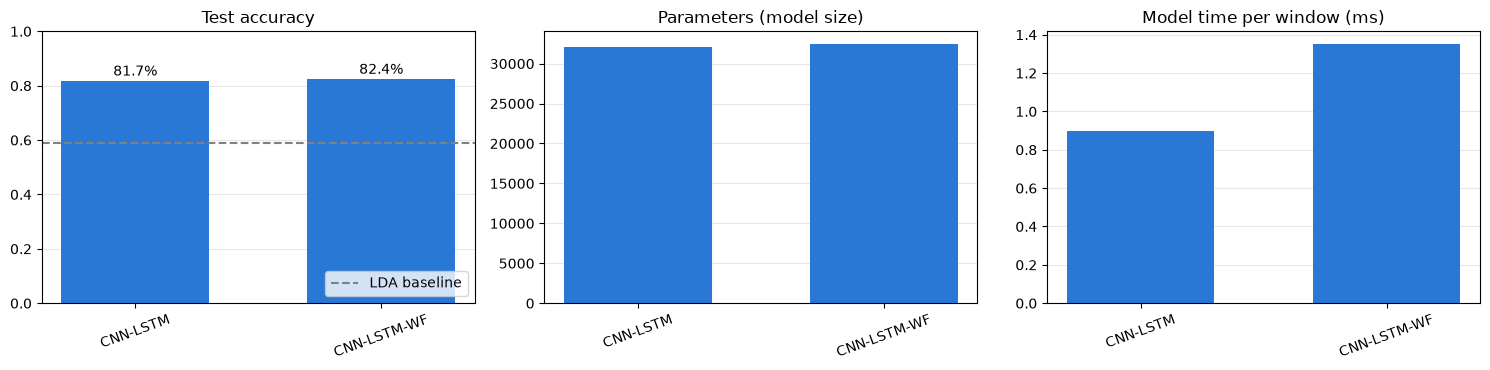

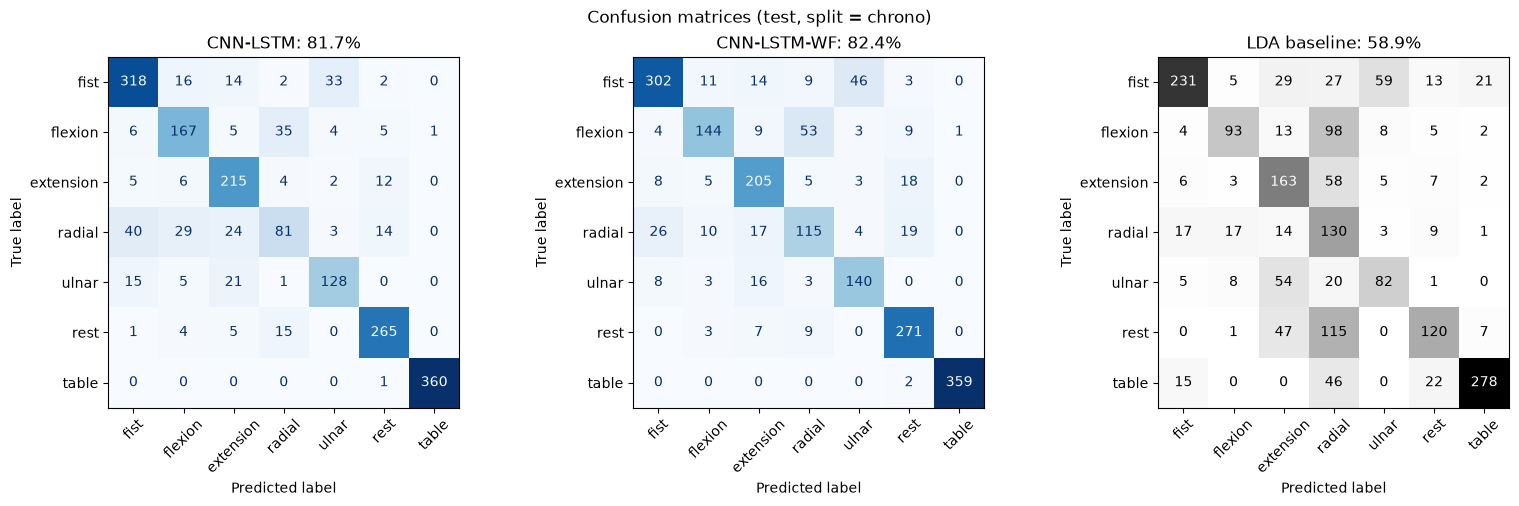

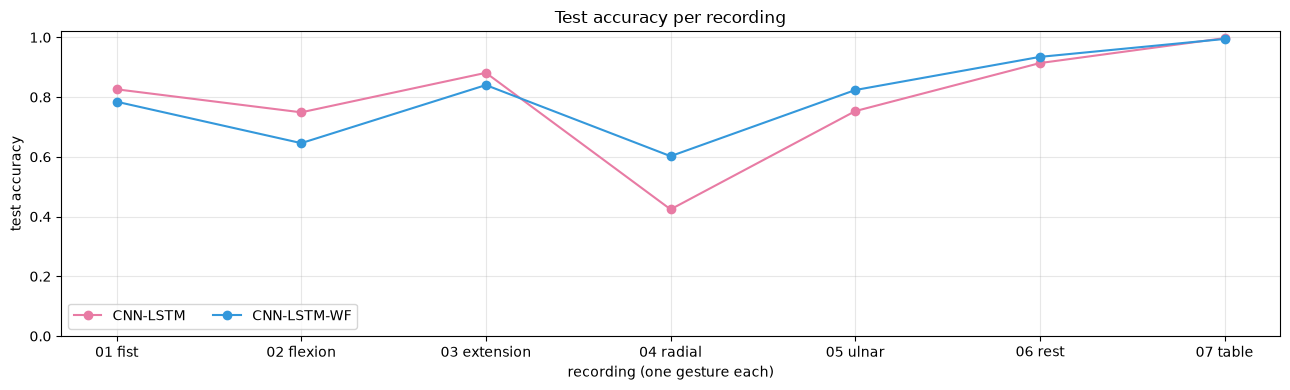

,,CNN-LSTM,CNN-LSTM-WF
recording,gesture,,
01,fist,82.6%,78.4%
02,flexion,74.9%,64.6%
03,extension,88.1%,84.0%
04,radial,42.4%,60.2%
05,ulnar,75.3%,82.4%
06,rest,91.4%,93.4%
07,table,99.7%,99.4%


Best model on the test set: CNN-LSTM-WF

              precision    recall  f1-score   support

        fist      0.868     0.784     0.824       385
     flexion      0.818     0.646     0.722       223
   extension      0.765     0.840     0.801       244
      radial      0.593     0.602     0.597       191
       ulnar      0.714     0.824     0.765       170
        rest      0.842     0.934     0.886       290
       table      0.997     0.994     0.996       361

    accuracy                          0.824      1864
   macro avg      0.800     0.804     0.799      1864
weighted avg      0.827     0.824     0.823      1864



In [24]:
# Draw every test result and get the best model's name (used by the save step).
per_file, best_name = result_illustration(results_table, test_predictions, lda_predictions,
                                          y_test, test_file, GESTURE_NAMES, COLOURS, SPLIT_BY)   # charts, tables, report

## Step 7: save everything needed to use the models later

The weights alone are not enough. Live data must go through exactly the same filters, window size and normalisation, so those settings are saved in the same file as each model, for example `CNN-LSTM_semg.pt`.

In [25]:
def save_model(name, model, channel_mean, channel_std, results_table):
    """
    What it does:
        Save a full checkpoint: the weights plus everything needed to rebuild the model and to
        prepare live windows exactly as in training. File: "{name}_semg.pt".

    Steps:
        1. Collect the weights, normalisation, preprocessing settings, window and gesture details,
           test scores and model settings in one dictionary.
        2. Save it with torch.save.
    """
    torch.save({ # rebuild with build_model(name, params=...)
        "model_name": name,                                  # which class to rebuild
        "model_weights": model.state_dict(),                 # trained weights
        "channel_mean": channel_mean.tolist(),     # plain lists, so torch.load works without extra flags
        "channel_std": channel_std.tolist(),
        "preprocessing": PREP,                     # every pp.preprocess setting
        "window_size": WINDOW_SIZE,                          # samples per window
        "step": STEP,                                        # samples between windows
        "gestures": GESTURE_NAMES,                           # class number -> gesture name
        "split": SPLIT_BY,                                   # how the data was split
        "test_accuracy": float(results_table.loc[name, "accuracy"]),   # mean over seeds
        "test_macro_f1": float(results_table.loc[name, "macro F1"]),   # mean over seeds
        "params": PARAMS[name]}, f"{name}_semg.pt")          # model + training settings
    print(f"saved {name}_semg.pt")

save_model(best_name, models[best_name], channel_mean, channel_std, results_table)   # save the best model only

saved CNN-LSTM-WF_semg.pt


### How much of this is temporal, and how much is just amplitude?

The sequence models only earn their place if they beat a classifier that cannot see time at
all. This fits an LDA to the per-channel RMS of each window — eight numbers, every trace of
temporal structure discarded — and to a single sample per window.

If the RMS score lands close to your best deep model, the task is being solved by "how hard
is each electrode reading", not by how the signal evolves, and the recurrent layers are
decoration. That is the expected result when every gesture is one long steady hold: there
are no onsets or transitions in the data for a sequence model to work with.

## Step 8: automated tuning with Optuna

In [26]:
%pip install optuna

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### How it works
Optuna tries many settings automatically. Each **trial** trains a model once (seed 0) with one set of
settings and is scored by its **best validation accuracy**. The test set is not used.

- **One search per model:** CNN-LSTM, CNN and LSTM are tuned separately, each with its own study.
- **Trial 0** = the current settings (`PARAMS`), so the starting point is scored the same way.
- **TPE sampler:** the first ~10 trials explore; later trials try settings close to the best so far.
- **Median pruner:** from trial 10 and epoch 5, a trial below the median of earlier trials is stopped.

### Search space
| Setting | Range | CNN-LSTM | CNN | LSTM |
|---|---|:-:|:-:|:-:|
| `lr` | 0.0001–0.01 (log) | ✓ | ✓ | ✓ |
| `weight_decay` | 0.000001–0.01 (log) | ✓ | ✓ | ✓ |
| `batch_size` | 32, 64, 128 | ✓ | ✓ | ✓ |
| `dropout` | 0.0–0.5 | ✓ | ✓ | ✓ |
| `width` | 16, 32, 64, 128 | ✓ | ✓ | |
| `kernel_size` | 3, 5, 7 | ✓ | ✓ | |
| `cnn_layers` / `n_layers` | 1–4 / 2–4 | ✓ | ✓ | |
| `stride` | 1, 2 | ✓ | | |
| `hidden` | 32, 64, 128, 256 | ✓ | | ✓ |
| `lstm_layers` / `layers` | 1–3 | ✓ | | ✓ |
| `use_features` | False, True | ✓ | | |

**Reach rule:** reach = `1 + (kernel_size − 1) × conv layers`. Settings with a reach over 2 × `WINDOW_SIZE`
are skipped (mostly padding). The CNN must also reach at least `WINDOW_SIZE`, since it has no LSTM to cover
the rest of the window.

**Trials:** CNN-LSTM 100, CNN 50, LSTM 50. Pruned trials count towards the total.

### Saving and resuming
- Every trial is saved in `tuning.db`; re-running the cell continues where it stopped.
- **Delete `tuning.db` when the data changes.**
- `results_before_tuning.csv` keeps the results from before tuning.

### Next
Run the next cell (`PARAMS = best_params`), then re-run Steps 5–7 (3 seeds, test once).

In [27]:
# ---------------------------------------------------------------------------------------------
# Step 8: automated tuning with Optuna
#
# What it does:
#     Search each model's settings automatically. Every trial trains one model (seed 0) with
#     suggested settings and is scored by its best validation accuracy. The test set is not used.
#
# Steps:
#     1. N_TRIALS: number of trials per model.
#     2. suggest_params: which settings each model may change, and their ranges.
#     3. For each model: create (or resume) a study saved in tuning.db.
#     4. Trial 0 = the current PARAMS, so the baseline is scored the same way.
#     5. Run the remaining trials; weak trials are stopped early by the pruner.
#     6. Store and print the best settings per model.
# ---------------------------------------------------------------------------------------------

import json                                                  # save the best settings
import optuna                                                # tuning library

N_TRIALS = {"CNN-LSTM": 20,                                 # 1. trials per model
            "CNN": 20,
            "LSTM": 20}


# Ranges of the settings to tune.
# p holds the settings shared by all models; model-specific settings are added below.
def suggest_params(trial, name):
    """
    What it does:
        Ask Optuna for one value of every tunable setting of the given model. Return the settings.

    Steps:
        1. Shared training settings: learning rate, weight decay, batch size, dropout.
        2. LSTM settings (LSTM, CNN-LSTM): memory size and number of layers.
        3. CNN settings (CNN, CNN-LSTM): filter count and filter size.
        4. CNN-LSTM only: stride and hand-made features on/off.
        5. CNN only: number of layers; skip layouts whose reach does not fit the window.
    """
    p = {"lr":           trial.suggest_float("lr", 1e-4, 1e-2, log=True),            # 1. log scale: 0.0001 .. 0.01
         "weight_decay": trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
         "batch_size":   trial.suggest_categorical("batch_size", [32, 64, 128]),
         "dropout":      trial.suggest_float("dropout", 0.0, 0.5)
        }

    if name in ("LSTM", "CNN-LSTM"):                                                   # 2.
        p["hidden"] = trial.suggest_categorical("hidden", [32, 64, 128])
        p["layers"] = trial.suggest_int("layers", 1, 2)

    if name in ("CNN", "CNN-LSTM"):                                                    # 3.
        p["width"] = trial.suggest_categorical("width", [16, 32, 64])
        p["kernel_size"] = trial.suggest_categorical("kernel_size", [3, 5, 7])

    if name == "CNN-LSTM":                                                             # 4.
        p["stride"] = trial.suggest_categorical("stride", [1, 2])
        p["use_features"] = trial.suggest_categorical("use_features", [False, True])

    if name == "CNN":                                                                  # 5.
        p["n_layers"] = trial.suggest_int("n_layers", 1, 4)
        reach = 1 + (p["kernel_size"] - 1) * p["n_layers"]       # samples the CNN can see
        if reach < WINDOW_SIZE or reach > 2 * WINDOW_SIZE:
            raise optuna.TrialPruned()                         # must cover the window, not much more
    return p


# Run the tuning for each model, saving the best parameters and validation accuracy
optuna.logging.set_verbosity(optuna.logging.WARNING)         # warnings only, no line per trial
results_table.to_csv("results_before_tuning.csv")            # keep the baseline results
best_params = {}                                             # best settings per model




# run trials for each model, using the objective function to train and evaluate the model with the suggested parameters
for name in MODEL_CLASSES:

    # objective function for the tuning, which trains the model and returns the best validation accuracy
    def objective(trial):
        history = train_model(name, seed=0, params=suggest_params(trial, name), trial=trial)   # one trial = one training run
        return max(history["val_acc"])                       # trial score


    study = optuna.create_study(direction="maximize",                           # 3. higher score is better
                                study_name=f"{name}_{WINDOW_MS}ms_{SAMPLE_RATE}Hz",     # label for the search in the save file
                                storage="sqlite:///tuning.db",                          # database file that keeps every trial
                                load_if_exists=True,                                    # can stop and resume
                                sampler=optuna.samplers.TPESampler(seed=0),             # method of choosing each trial's settings
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=5))   # early stop of weak trials


    if len(study.trials) == 0:                               # 4. new study only
        study.enqueue_trial(PARAMS[name])                    #    trial 0 = the current settings
    done = sum(t.state.is_finished() for t in study.trials)  #    trials already finished (when resuming)
    study.optimize(objective, n_trials=max(0, N_TRIALS[name] - done), show_progress_bar=True)   # 5. run the rest



    best_params[name] = study.best_params                    # 6. best settings found
    print(f"{name}: best validation accuracy {study.best_value:.1%}  {study.best_params}")

c:\Users\micha\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CNN-LSTM: best validation accuracy 86.1%  {'lr': 0.004303315323222227, 'weight_decay': 0.007517110864521361, 'batch_size': 32, 'dropout': 0.03160315129726133, 'hidden': 128, 'layers': 1, 'width': 32, 'kernel_size': 5, 'stride': 2, 'use_features': True}


KeyError: 'CNN-LSTM-WF'

In [ ]:
# ---------------------------------------------------------------------------------------------
# Use the tuned settings
#
# What it does:
#     Replace PARAMS with the best settings found by the search and save them to a file.
#     Then re-run the training loop (Step 5) to Step 7 for the tuned results.
# ---------------------------------------------------------------------------------------------

PARAMS = best_params                                                 # tuned settings for every model
json.dump(PARAMS, open("best_params.json", "w"), indent=1)           # keep a copy on disk
print("Now re-run Step 5 (the training loop) to Step 7 to train the tuned models with every seed and test once.")